In [4]:
import csv
import numpy as np
from typing import Set,Tuple, List
import torch
import torch.utils
import torch.utils.data
import torch.nn as nn
import torchvision
NoneType = type(None)
import matplotlib.pyplot as plt
from IPython.display import display, clear_output
from PIL import Image
import torchvision.transforms.functional as TF
from torchvision.models import vgg11
from torchvision.models import mobilenet_v2
import torchvision.transforms as transforms
import time


In [5]:
import torch
print("GPU available:", torch.cuda.is_available())

GPU available: True


<h1 id="exercise-1"><strong>Exercise 1</strong></h1>


<font size="4px"><p>This method returns the fruit name by getting the string at a specific index of the set.</p>
<dl>
<dt>param fruit_id</dt>
<dd><p>The id of the fruit to get</p>
</dd>
<dt>param fruits</dt>
<dd><p>The set of fruits to choose the id from</p>
</dd>
<dt>return</dt>
<dd><p>The string corrosponding to the index <code>fruit_id</code></p>
</dd>
</dl>
<p><strong>This method is part of a series of debugging exercises.</strong> <strong>Each Python method of this series contains bug that needs to be found.</strong></p>
<div class="line-block"><code>1   It does not print the fruit at the correct index, why is the returned result wrong?</code><br />
<code>2   How could this be fixed?</code></div>
<p>This example demonstrates the issue: name1, name3 and name4 are expected to correspond to the strings at the indices 1, 3, and 4: 'orange', 'kiwi' and 'strawberry'..</p>
</font>

In [6]:
# You can copy this code to your personal pipeline project or execute it here.
def id_to_fruit(fruit_id: int, fruits: List[str]) -> str:
    """
    Returns the fruit name at position `fruit_id`.

    FIX: `fruits` is now a LIST (ordered) instead of a SET (unordered).
    A list always keeps the same order, so index 1 is always the same fruit.

    >>> id_to_fruit(1, ["apple", "orange", "melon", "kiwi", "strawberry"])
    'orange'
    """
    # Check that the id is a valid position in the list (0 up to length - 1)
    if fruit_id < 0 or fruit_id >= len(fruits):
        raise RuntimeError(f"Fruit with id {fruit_id} does not exist")

    # Lists can be read by position directly
    return fruits[fruit_id]

In [7]:
#we now pass a list instead of a set
fruit_list = ["apple", "orange", "melon", "kiwi", "strawberry"]

name1 = id_to_fruit(1, fruit_list)
name3 = id_to_fruit(3, fruit_list)
name4 = id_to_fruit(4, fruit_list)

print(name1, name3, name4)

orange kiwi strawberry


1. The returned result is wrong because a Python `set` has no order, so it has no real "index". Looping over a set gives the items in an arbitrary order that can differ between runs, so position 1 is not necessarily "orange".
2. Use an ordered container such as a `list` (or `tuple`) instead of a set, and read the fruit directly with `fruits[fruit_id]`.

<h1 id="exercise-2"><strong>Exercise 2</strong></h1>


<font size="4px"><p>This method will flip the x and y coordinates in the coords array.</p>
<dl>
<dt>param coords</dt>
<dd><p>A numpy array of bounding box coordinates with shape [n,5] in format: :</p>
<pre><code>[[x11, y11, x12, y12, classid1],
 [x21, y21, x22, y22, classid2],
 ...
 [xn1, yn1, xn2, yn2, classid3]]</code></pre>
</dd>
<dt>return</dt>
<dd><p>The new numpy array where the x and y coordinates are flipped.</p>
</dd>
</dl>
<p><strong>This method is part of a series of debugging exercises.</strong> <strong>Each Python method of this series contains bug that needs to be found.</strong></p>
<div class="line-block"><code>1   Can you spot the obvious error?</code><br />
<code>2   After fixing the obvious error it is still wrong, how can this be fixed?</code></div>
</font>

<font size="4px"><p>The example demonstrates the issue. The returned swapped_coords are expected to have swapped x and y coordinates in each of the rows.</p>
</font>

In [8]:
# You can copy this code to your personal pipeline project or execute it here.
def swap(coords: np.ndarray):
    """
    Swaps x and y in every bounding box row.
    Row format: [x1, y1, x2, y2, classid]  ->  [y1, x1, y2, x2, classid]

    FIX 1: the old code used coords[:, 1] twice. Now each column is used once.
    FIX 2: numpy slices are "views" of the same data, so we write into a
           separate COPY while reading from the untouched original.
    """
    new_coords = coords.copy()
    new_coords[:, 0] = coords[:, 1]
    new_coords[:, 1] = coords[:, 0]
    new_coords[:, 2] = coords[:, 3]
    new_coords[:, 3] = coords[:, 2]
    return new_coords

In [9]:
import numpy as np
coords = np.array([[10, 5, 15, 6, 0],
                   [11, 3, 13, 6, 0],
                   [5, 3, 13, 6, 1],
                   [4, 4, 13, 6, 1],
                   [6, 5, 13, 16, 1]])
swapped_coords = swap(coords)

print("Original:")
print(coords)
print("Swapped:")
print(swapped_coords)

Original:
[[10  5 15  6  0]
 [11  3 13  6  0]
 [ 5  3 13  6  1]
 [ 4  4 13  6  1]
 [ 6  5 13 16  1]]
Swapped:
[[ 5 10  6 15  0]
 [ 3 11  6 13  0]
 [ 3  5  6 13  1]
 [ 4  4  6 13  1]
 [ 5  6 16 13  1]]


1. The obvious error is that `coords[:, 1]` appears twice on the right side. Column 0 and column 1 both receive the old y value, and the old x value is lost. The right side should be `coords[:, 1], coords[:, 0], coords[:, 3], coords[:, 2]`.
2. After fixing that it is still wrong because numpy slices are views of the same memory, not copies. The first assignment overwrites column 0 of the original array, so the second assignment reads data that has already changed. The fix is to read from the original array and write the results into a copy (`coords.copy()`).

<h1 id="exercise-3"><strong>Exercise 3</strong></h1>


<font size="4px"><p>This code plots the precision-recall curve based on data from a .csv file, where precision is on the x-axis and recall is on the y-axis. It it not so important right now what precision and recall means.</p>
<dl>
<dt>param csv_file_path</dt>
<dd><p>The CSV file containing the data to plot.</p>
</dd>
</dl>
<p><strong>This method is part of a series of debugging exercises.</strong> <strong>Each Python method of this series contains bug that needs to be found.</strong></p>
<div class="line-block"><code>1   For some reason the plot is not showing correctly, can you find out what is going wrong?</code><br />
<code>2   How could this be fixed?</code></div>
<p>This example demonstrates the issue. It first generates some data in a csv file format and the plots it using the <code>plot_data</code> method. If you manually check the coordinates and then check the plot, they do not correspond.</p>
</font>

In [10]:
# You can copy this code to your personal pipeline project or execute it here.
def plot_data(csv_file_path: str):
    """
    Plots the precision-recall curve from a CSV file.
    Precision is on the x-axis and recall is on the y-axis.

    FIX 1: values read from a CSV are text. We convert them to float numbers.
    FIX 2: columns are [precision, recall], so precision (column 0) goes on x
           and recall (column 1) goes on y, as the description says.
    FIX 3: on Windows the file can contain empty lines between rows,
           so we skip any empty row.
    """
    # load data
    results = []
    with open(csv_file_path) as result_csv:
        csv_reader = csv.reader(result_csv, delimiter=',')
        next(csv_reader)
        for row in csv_reader:
            if not row:
                continue
            results.append([float(value) for value in row])
        results = np.array(results)
    plt.plot(results[:, 0], results[:, 1])
    plt.ylim([-0.05, 1.05])
    plt.xlim([-0.05, 1.05])
    plt.xlabel('Precision')
    plt.ylabel('Recall')
    plt.show()

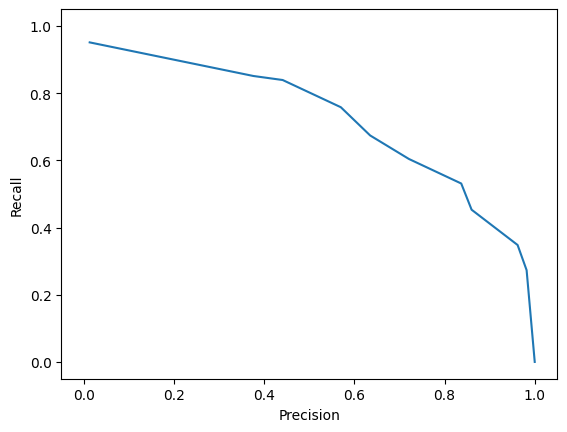

In [11]:
f = open("data_file.csv", "w")
w = csv.writer(f)
_ = w.writerow(["precision", "recall"])
w.writerows([[0.013,0.951],
             [0.376,0.851],
             [0.441,0.839],
             [0.570,0.758],
             [0.635,0.674],
             [0.721,0.604],
             [0.837,0.531],
             [0.860,0.453],
             [0.962,0.348],
             [0.982,0.273],
             [1.0,0.0]])
f.close()
plot_data('data_file.csv')


1. Values read with the `csv` module are strings. `np.stack` therefore creates an array of text, and matplotlib treats text as categories placed at equal distances, so the plotted points do not match the real numbers.
2. Convert every value to `float` while reading the file. The plot also now matches the description, with precision on the x-axis and recall on the y-axis. I also skip empty rows, because on Windows the written CSV contains blank lines between rows.

<h1 id="generator-for-exercise-4">** Generator (for Exercise 4)**</h1>


<font size="4px"><p>Generator class for the GAN</p>
</font>

In [12]:
# You can copy this code to your personal pipeline project or execute it here.
class Generator(nn.Module):
    """
    Generator class for the GAN
    """

    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(100, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 1024),
            nn.ReLU(),
            nn.Linear(1024, 784),
            nn.Tanh(),
        )

    def forward(self, x):
        output = self.model(x)
        output = output.view(x.size(0), 1, 28, 28)
        return output



<h1 id="discriminator-for-exercise-4">** Discriminator (for Exercise 4)**</h1>


<font size="4px"><p>Discriminator class for the GAN</p>
</font>

In [13]:
# You can copy this code to your personal pipeline project or execute it here.
class Discriminator(nn.Module):
    """
    Discriminator class for the GAN
    """
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(784, 1024),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        x = x.view(x.size(0), 784)
        output = self.model(x)
        return output



<h1 id="exercise-4">** Exercise 4**</h1>


<font size="4px"><p>The method trains a Generative Adversarial Network and is based on: <a href="https://realpython.com/generative-adversarial-networks/">https://realpython.com/generative-adversarial-networks/</a></p>
<p>The Generator network tries to generate convincing images of handwritten digits. The Discriminator needs to detect if the image was created by the Generater or if the image is a real image from a known dataset (MNIST). If both the Generator and the Discriminator are optimized, the Generator is able to create images that are difficult to distinguish from real images. This is goal of a GAN.</p>
<p>This code produces the expected results at first attempt at about 50 epochs.</p>
<dl>
<dt>param batch_size</dt>
<dd><p>The number of images to train in one epoch.</p>
</dd>
<dt>param num_epochs</dt>
<dd><p>The number of epochs to train the gan.</p>
</dd>
<dt>param device</dt>
<dd><p>The computing device to use. If CUDA is installed and working then <span class="title-ref">cuda:0</span> is chosen otherwise 'cpu' is chosen. Note: Training a GAN on the CPU is very slow.</p>
</dd>
</dl>
<p><strong>This method is part of a series of debugging exercises.</strong> <strong>Each Python method of this series contains bug that needs to be found.</strong></p>
<p>It contains at least two bugs: one structural bug and one cosmetic bug. Both bugs are from the original tutorial.</p>
<div class="line-block"><code>1   Changing the batch_size from 32 to 64 triggers the structural bug.</code><br />
<code>2   Can you also spot the cosmetic bug?</code><br />
<code>Note: to fix this bug a thorough understanding of GANs is not necessary.</code></div>
<p>Change the batch size to 64 to trigger the bug with message: ValueError: "Using a target size (torch.Size([128, 1])) that is different to the input size (torch.Size([96, 1])) is deprecated. Please ensure they have the same size."</p>
</font>

In [17]:
# You can copy this code to your personal pipeline project or execute it here.
def train_gan(batch_size: int = 32, num_epochs: int = 100, device: str = "cuda:0" if torch.cuda.is_available() else "cpu"):
    """
    Trains a Generative Adversarial Network on MNIST handwritten digits.
    Based on: https://realpython.com/generative-adversarial-networks/

    FIX 1 (structural): labels and noise use the REAL size of each batch,
          because the last batch of an epoch can be smaller than batch_size.
    FIX 2 (cosmetic): progress is shown once at the END of each epoch,
          not at batch number (batch_size - 1).
    FIX 3 (clean-up): figures are closed after showing, so they do not pile up.

    >>> train_gan(batch_size=32, num_epochs=100)
    """
    transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])

    try:
        train_set = torchvision.datasets.MNIST(root=".", train=True, download=True, transform=transform)
    except:
        print("Failed to download MNIST, retrying with different URL")
        # see: https://github.com/pytorch/vision/blob/master/torchvision/datasets/mnist.py
        torchvision.datasets.MNIST.resources = [
            ('https://ossci-datasets.s3.amazonaws.com/mnist/train-images-idx3-ubyte.gz',
             'f68b3c2dcbeaaa9fbdd348bbdeb94873'),
            ('https://ossci-datasets.s3.amazonaws.com/mnist/train-labels-idx1-ubyte.gz',
             'd53e105ee54ea40749a09fcbcd1e9432'),
            ('https://ossci-datasets.s3.amazonaws.com/mnist/t10k-images-idx3-ubyte.gz',
             '9fb629c4189551a2d022fa330f9573f3'),
            ('https://ossci-datasets.s3.amazonaws.com/mnist/t10k-labels-idx1-ubyte.gz',
             'ec29112dd5afa0611ce80d1b7f02629c')
        ]
        train_set = torchvision.datasets.MNIST(root=".", train=True, download=True, transform=transform)

    train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size, shuffle=True)

    real_samples, mnist_labels = next(iter(train_loader))

    fig = plt.figure()
    for i in range(16):
        sub = fig.add_subplot(4, 4, 1 + i)
        sub.imshow(real_samples[i].reshape(28, 28), cmap="gray_r")
        sub.axis('off')

    fig.tight_layout()
    fig.suptitle("Real images")
    display(fig)
    plt.close(fig)

    time.sleep(5)
    discriminator = Discriminator().to(device)
    generator = Generator().to(device)
    lr = 0.0001
    loss_function = nn.BCELoss()
    optimizer_discriminator = torch.optim.Adam(discriminator.parameters(), lr=lr)
    optimizer_generator = torch.optim.Adam(generator.parameters(), lr=lr)
    for epoch in range(num_epochs):
        for n, (real_samples, mnist_labels) in enumerate(train_loader):

            current_batch_size = real_samples.size(0)

            real_samples = real_samples.to(device=device)
            real_samples_labels = torch.ones((current_batch_size, 1)).to(device=device)
            latent_space_samples = torch.randn((current_batch_size, 100)).to(device=device)
            generated_samples = generator(latent_space_samples)
            generated_samples_labels = torch.zeros((current_batch_size, 1)).to(device=device)
            all_samples = torch.cat((real_samples, generated_samples))
            all_samples_labels = torch.cat((real_samples_labels, generated_samples_labels))

            discriminator.zero_grad()
            output_discriminator = discriminator(all_samples)
            loss_discriminator = loss_function(output_discriminator, all_samples_labels)
            loss_discriminator.backward()
            optimizer_discriminator.step()
            latent_space_samples = torch.randn((current_batch_size, 100)).to(device=device)

            generator.zero_grad()
            generated_samples = generator(latent_space_samples)
            output_discriminator_generated = discriminator(generated_samples)
            loss_generator = loss_function(output_discriminator_generated, real_samples_labels)
            loss_generator.backward()
            optimizer_generator.step()

            if n == len(train_loader) - 1:
                name = f"Generate images\n Epoch: {epoch} Loss D.: {loss_discriminator.item():.2f} Loss G.: {loss_generator.item():.2f}"
                generated_samples = generated_samples.detach().cpu().numpy()
                fig = plt.figure()
                for i in range(min(16, len(generated_samples))):
                    sub = fig.add_subplot(4, 4, 1 + i)
                    sub.imshow(generated_samples[i].reshape(28, 28), cmap="gray_r")
                    sub.axis('off')
                fig.suptitle(name)
                fig.tight_layout()
                clear_output(wait=False)
                display(fig)
                plt.close(fig)

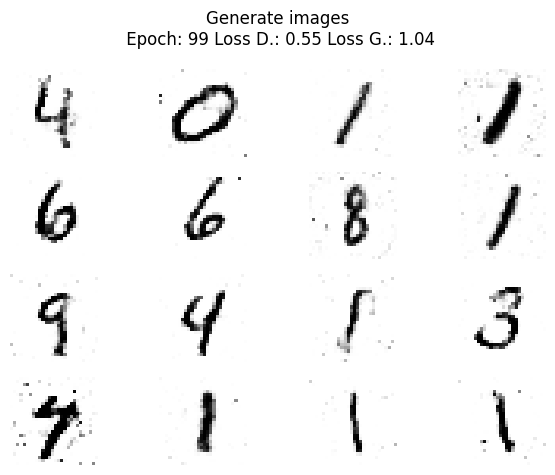

In [18]:
train_gan(batch_size=32, num_epochs=100)


1. Structural bug: the labels and random noise were created with the fixed `batch_size`, but the last batch of the dataset is smaller (with batch size 64 it holds 32 images). The discriminator then receives 32 real + 64 fake = 96 samples but 128 labels, which raises the `ValueError`. The fix is to use `real_samples.size(0)`, the actual size of the current batch, for the labels and the noise.
2. Cosmetic bug: `if n == batch_size - 1` was meant to show the losses and images at the end of each epoch, but it compares the batch counter to the batch size, so it fires at an arbitrary batch. The fix is `if n == len(train_loader) - 1`. I also close each figure after displaying it so figures do not pile up.